In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

df = pd.read_csv("train.csv")


print("First five rows of the dataset:")
display(df.head())


print("\nDataset Information")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


print("\nColumn names and data types:")
df.info()




First five rows of the dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Information
Number of rows: 1460
Number of columns: 81

Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  Ho

In [6]:
print("\nMissing Values Analysis:")

missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

if missing_values.empty:
    print("No missing values found.")
else:
    display(missing_values.to_frame(name="Missing Count"))


Missing Values Analysis:


,Missing Count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [7]:
print("Descriptive Statistics for Numerical Features:")
display(df.describe().T)
print("\nHouse Sale Price Statistics:")
display(df["SalePrice"].describe())


Descriptive Statistics for Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



House Sale Price Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Distribution of House Sale Prices


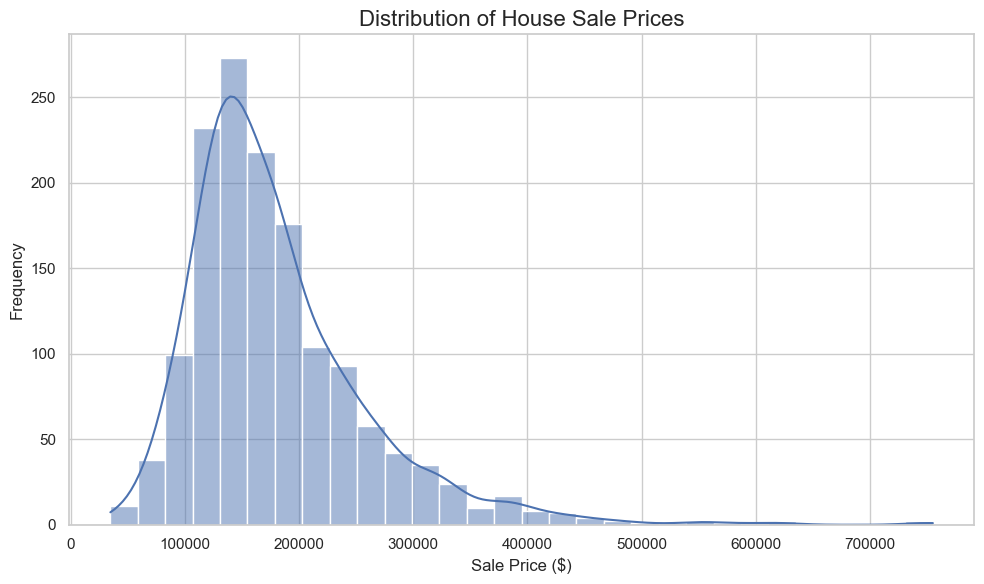

In [8]:
print("Distribution of House Sale Prices")
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="SalePrice",
    bins=30,
    kde=True
)
plt.title("Distribution of House Sale Prices", fontsize=16)
plt.xlabel("Sale Price ($)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.tight_layout()
plt.show()

## Feature Selection

The target variable is `SalePrice`, which represents the selling price of each house.

The following features are selected as potential predictors:

- `OverallQual`: Represents the overall material and finish quality of the house.
- `GrLivArea`: Represents above-ground living area in square feet.
- `TotalBsmtSF`: Represents the total basement area.
- `GarageCars`: Represents the number of cars that can fit in the garage.
- `YearBuilt`: Represents the year the house was constructed.
- `FullBath`: Represents the number of full bathrooms.
- `BedroomAbvGr`: Represents the number of bedrooms above ground.
- `Neighborhood`: Represents the location of the property.

These features are selected because house size, quality, location, and facilities may influence selling price. The `Id` column is excluded because it is an identifier rather than a meaningful property characteristic.

Correlation analysis will be used to examine relationships between numerical features and `SalePrice`. Correlation does not necessarily imply causation.

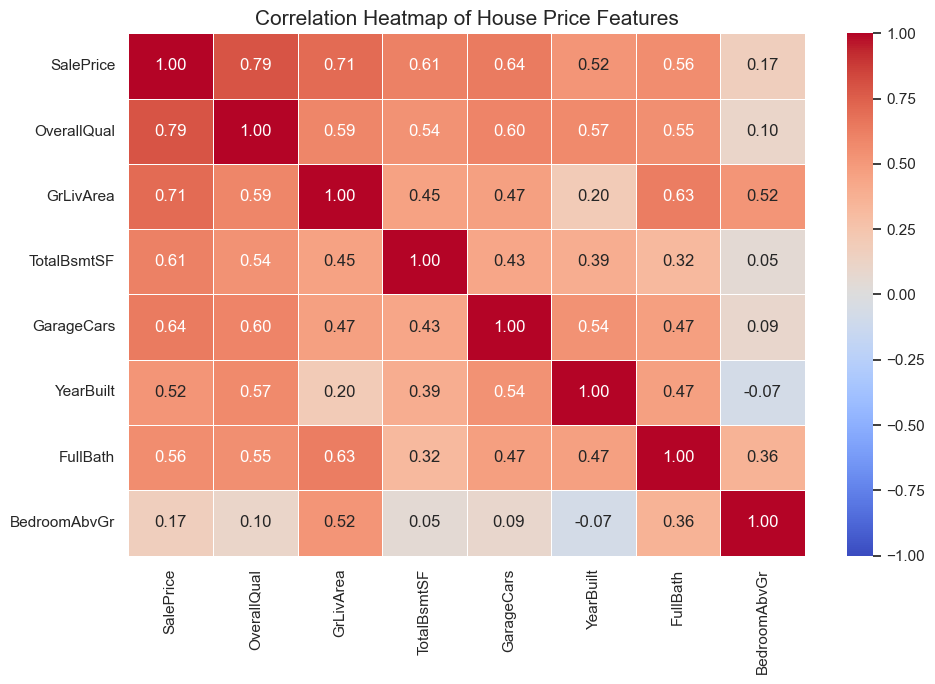

In [9]:
# Correlation HeatMap
numeric_features = [
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr"
]
correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of House Price Features", fontsize=15)
plt.tight_layout()
plt.show()


In [10]:
# Correlation of features with SalePrice
price_correlation = (
    correlation_matrix["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("Features most positively correlated with SalePrice:")
display(price_correlation.to_frame("Correlation"))

print("\nStrongest positive relationship:")
print(price_correlation.idxmax(), ":", round(price_correlation.max(), 3))

print("\nStrongest negative relationship:")
print(price_correlation.idxmin(), ":", round(price_correlation.min(), 3))


Features most positively correlated with SalePrice:


,Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
TotalBsmtSF,0.613581
FullBath,0.560664
YearBuilt,0.522897
BedroomAbvGr,0.168213



Strongest positive relationship:
OverallQual : 0.791

Strongest negative relationship:
BedroomAbvGr : 0.168


## Correlation Analysis — Observations

A correlation heatmap was generated to examine the linear relationships between selected numerical housing features and the target variable, `SalePrice`.

Features with stronger positive correlations may be useful predictors of house prices. Features with weaker correlations may still contribute useful information when combined with other variables.

The correlation results will help guide feature selection, but they do not establish causal relationships. Categorical features such as `Neighborhood` will be incorporated separately through One-Hot Encoding.

In [11]:
#Preparing Data for Machine Learning
features = [
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr",
    "Neighborhood"
]

# Input variables (X)
X = df[features]

# Target variable (y)
y = df["SalePrice"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (1460, 8)
Target variable shape: (1460,)


,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt,FullBath,BedroomAbvGr,Neighborhood
0,7,1710,856,2,2003,2,3,CollgCr
1,6,1262,1262,2,1976,2,3,Veenker
2,7,1786,920,2,2001,2,3,CollgCr
3,7,1717,756,3,1915,1,3,Crawfor
4,8,2198,1145,3,2000,2,4,NoRidge


0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64

In [12]:
from sklearn.model_selection import train_test_split
# Split the dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (1168, 8)
Testing data: (292, 8)
Training target: (1168,)
Testing target: (292,)


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Separate numerical and categorical features
numeric_features = [
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr"
]

categorical_features = ["Neighborhood"]

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Data Preparation and Preprocessing

The selected features are divided into input variables (`X`) and the target variable (`SalePrice`), which represents the house selling price.

The dataset is split into training and testing sets using an 80:20 ratio. The training set is used to build the model, while the testing set evaluates its performance on unseen data.

Missing numerical values are handled using median imputation, and missing categorical values are filled using the most frequent category. The categorical feature `Neighborhood` is converted into numerical columns using One-Hot Encoding.

A preprocessing pipeline is used to keep these transformations consistent and prevent data leakage.

In [14]:
#Train the Linear Regression Model
from sklearn.linear_model import LinearRegression
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [15]:
#Predict House Prices
y_pred = model.predict(X_test)

print("First 10 Actual House Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted House Prices:")
print(np.round(y_pred[:10], 2))

First 10 Actual House Prices:
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]

First 10 Predicted House Prices:
[141058.89 329259.81 114656.22 180039.43 284802.13  61540.54 228433.74
 152125.09  61020.03 123932.22]


In [16]:
#Evaluate Model Performance
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("----------------------------------")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R-squared (R²): {r2:.4f}")
print(f"R-squared percentage: {r2 * 100:.2f}%")

Linear Regression Model Evaluation
----------------------------------
Mean Squared Error (MSE): 1301609433.17
Root Mean Squared Error (RMSE): $36,077.82
R-squared (R²): 0.8303
R-squared percentage: 83.03%


## Linear Regression Model Training and Evaluation

A Linear Regression model was trained using the selected housing features. The preprocessing pipeline handles missing values and converts categorical features into numerical representations before training.

The trained model predicts house prices for the test dataset, which was not used during training.

Model performance is evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). These metrics help assess the accuracy of the predictions and the model's ability to explain variations in house prices.

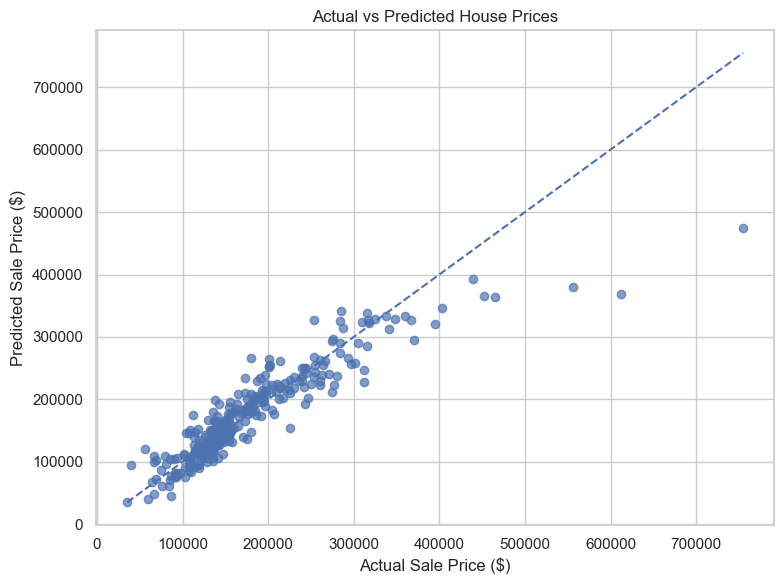

In [17]:
#Actual vs Predicted House Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)
plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")

plt.tight_layout()
plt.show()

## Actual vs. Predicted House Prices

A scatter plot was created to compare the actual house sale prices with the prices predicted by the Linear Regression model.

The dashed diagonal line represents perfect predictions, where the predicted price equals the actual price. Points closer to this line indicate more accurate predictions, while points farther away indicate larger prediction errors.

This visualization helps assess how well the model predicts house prices on the test dataset.

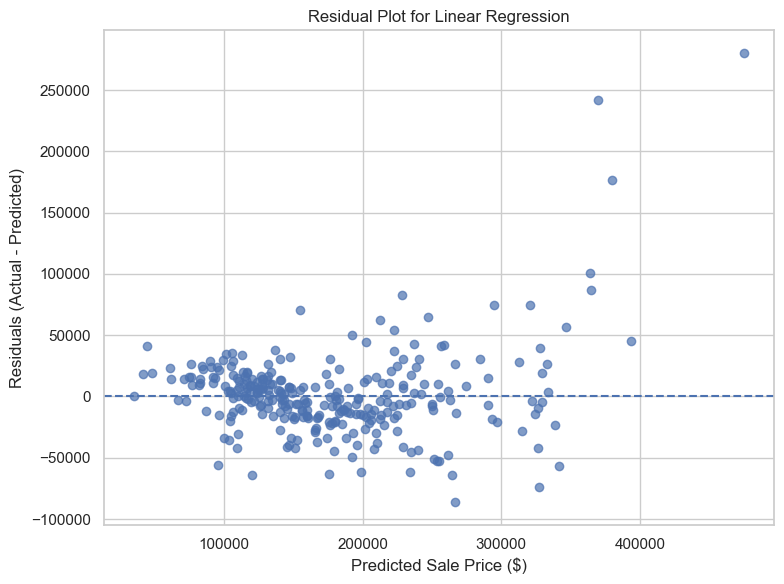

In [18]:
#Residual Plot

# Calculate residuals
residuals = y_test - y_pred

# Plot residuals against predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)

# Reference line at zero
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot for Linear Regression")
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()

## Residual Analysis

Residuals are calculated by subtracting the predicted house prices from the actual house prices.

A residual plot helps identify patterns in the prediction errors. Ideally, the residuals should be randomly scattered around the zero line without a clear pattern.

A positive residual means the model underestimated the actual house price, while a negative residual means it overestimated the price. Patterns or increasing spread in the residuals may indicate that the model does not capture all relationships in the data.

In [19]:
#Linear Regression Coefficient Analysis
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["regressor"].coef_
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})
coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)
print("Top 10 Features with the Largest Positive Coefficients:")
display(coef_df.head(10))

print("Top 10 Features with the Largest Negative Coefficients:")
display(coef_df.tail(10).sort_values(by="Coefficient"))

Top 10 Features with the Largest Positive Coefficients:


,Feature,Coefficient
29,cat__Neighborhood_StoneBr,47264.038824
23,cat__Neighborhood_NridgHt,45770.577747
22,cat__Neighborhood_NoRidge,44851.615435
31,cat__Neighborhood_Veenker,37164.485345
11,cat__Neighborhood_ClearCr,24173.448793
13,cat__Neighborhood_Crawfor,20722.941719
0,num__OverallQual,15395.258170
30,cat__Neighborhood_Timber,14032.238659
3,num__GarageCars,12442.235062
28,cat__Neighborhood_Somerst,4059.767227


Top 10 Features with the Largest Negative Coefficients:


,Feature,Coefficient
9,cat__Neighborhood_BrDale,-39727.409132
7,cat__Neighborhood_Blmngtn,-26351.021848
20,cat__Neighborhood_NPkVill,-24687.525383
17,cat__Neighborhood_MeadowV,-20405.925584
24,cat__Neighborhood_OldTown,-19271.180359
14,cat__Neighborhood_Edwards,-15672.225058
8,cat__Neighborhood_Blueste,-12446.879303
21,cat__Neighborhood_NWAmes,-12312.737296
16,cat__Neighborhood_IDOTRR,-12279.933633
25,cat__Neighborhood_SWISU,-11523.370302


# Visualize the Largest Coefficients

top_positive = coef_df.nlargest(10, "Coefficient")
top_negative = coef_df.nsmallest(10, "Coefficient")

selected_coefficients = pd.concat([
    top_negative,
    top_positive
]).drop_duplicates(subset="Feature")

plt.figure(figsize=(11, 8))

sns.barplot(
    data=selected_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Largest Positive and Negative Linear Regression Coefficients")
plt.xlabel("Coefficient Value ($)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

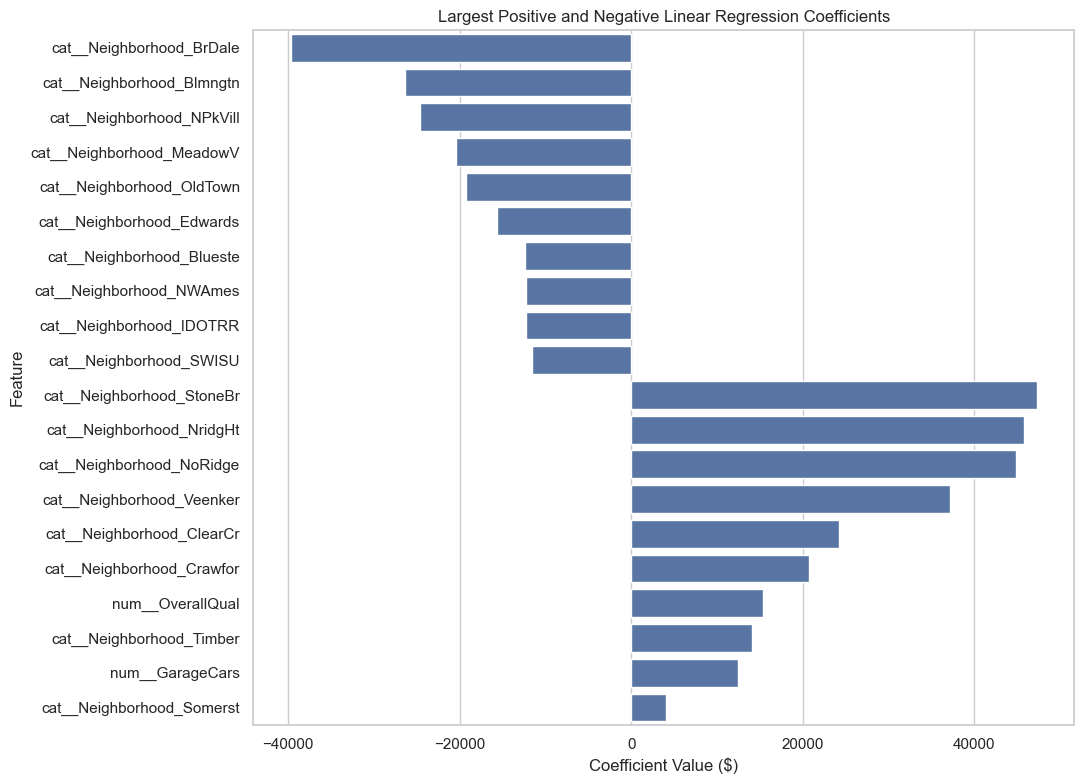

In [21]:
# Visualize the Largest Coefficients

top_positive = coef_df.nlargest(10, "Coefficient")
top_negative = coef_df.nsmallest(10, "Coefficient")

selected_coefficients = pd.concat([
    top_negative,
    top_positive
]).drop_duplicates(subset="Feature")

plt.figure(figsize=(11, 8))

sns.barplot(
    data=selected_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Largest Positive and Negative Linear Regression Coefficients")
plt.xlabel("Coefficient Value ($)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [22]:
#Ridge Regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
print("Ridge Regression model trained successfully!")

Ridge Regression model trained successfully!


In [23]:
# Compare Linear Regression and Ridge Regression

# Linear Regression metrics
lr_mse = mean_squared_error(y_test, y_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, y_pred)

# Ridge Regression metrics
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

# comparison table
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "MSE": [lr_mse, ridge_mse],
    "RMSE": [lr_rmse, ridge_rmse],
    "R2 Score": [lr_r2, ridge_r2]
})

display(comparison.round(4))

,Model,MSE,RMSE,R2 Score
0,Linear Regression,1.301609e+09,36077.8247,0.8303
1,Ridge Regression,1.501971e+09,38755.2664,0.8042


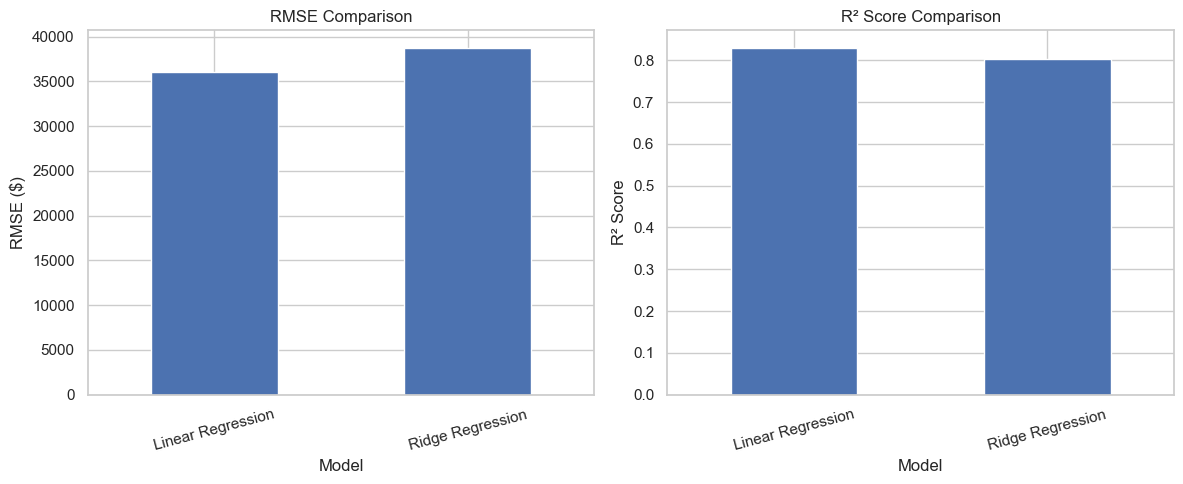

In [24]:
# Compare Model Performance Visually

comparison_plot = comparison.set_index("Model")[["RMSE", "R2 Score"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

comparison_plot["RMSE"].plot(
    kind="bar",
    ax=axes[0],
    title="RMSE Comparison"
)
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis="x", rotation=15)

comparison_plot["R2 Score"].plot(
    kind="bar",
    ax=axes[1],
    title="R² Score Comparison"
)
axes[1].set_ylabel("R² Score")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## Results and Model Comparison

The comparison shows that Linear Regression performs better than Ridge Regression on the test dataset.

Linear Regression achieves a lower Root Mean Squared Error (RMSE) and a higher R² score. Its RMSE is approximately $36,078, and its R² score is 0.8303, indicating that the model explains approximately 83.03% of the variation in house prices.

Ridge Regression has a slightly higher RMSE and a lower R² score for the selected regularization parameter (`alpha = 10.0`). Therefore, Linear Regression is the better-performing model among the two models evaluated in this experiment.

The results may vary with different feature selections, preprocessing methods, and model parameters.